# Comparación NLTK vs spaCy (POS tagging en español)

**Dataset:** `resenas_es 1.csv`  |  **Columna:** `review_summary_es`

Contenido:
1. Configuración y carga de modelos
2. Mapeo de etiquetas EAGLES → UPOS y funciones de etiquetado
3. Carga de datos
4. Comparación lado a lado (ejemplos)
5. Procesamiento completo y medición de tiempo
6. Métricas y resumen global
7. Exportar resultados y gráfico

## 0. Instalación (opcional)
Descomenta la primera vez. El modelo de spaCy se descarga aparte.

In [ ]:
# !pip install nltk spacy pandas matplotlib
# !python -m spacy download es_core_news_md

## 1. Importaciones y configuración

In [9]:
import time
import sys
import difflib
from collections import Counter
from pathlib import Path
import pandas as pd
import nltk
import spacy
import matplotlib.pyplot as plt
from nltk import word_tokenize
from nltk.corpus import cess_esp
from nltk.tag import UnigramTagger, BigramTagger, DefaultTagger

# ----------------------------------------------------------------------------
# CONFIGURACIÓN
# ----------------------------------------------------------------------------
CSV_PATH = "../processed/resenas_es.csv"
COLUMN = "review_summary_es"
N_EJEMPLOS = 3          # reseñas mostradas en formato tabla
MAX_FILAS = None        # p.ej. 5000 para limitar; None = todo el dataset
SPACY_MODEL = "es_core_news_md"   # alternativas: es_core_news_sm / lg / trf
EXPORTAR_CSV = True     # guardar comparacion_nltk_spacy_resultados.csv

for res in ["punkt", "punkt_tab", "cess_esp"]:
    nltk.download(res, quiet=True)

## 2. Modelos

NLTK no trae etiquetador para español: se entrena uno con `cess_esp` (etiquetas EAGLES, p. ej. `nc0s000` = sustantivo común singular). spaCy usa un modelo preentrenado.

In [3]:
nlp = spacy.load(SPACY_MODEL)

t0 = time.perf_counter()
train = [[(w, t) for w, t in sent if t] for sent in cess_esp.tagged_sents()]
_t0 = DefaultTagger("nc0s000")
_t1 = UnigramTagger(train, backoff=_t0)
nltk_tagger = BigramTagger(train, backoff=_t1)
t_train = time.perf_counter() - t0

print(f"Tagger NLTK entrenado en {t_train:.2f} s")

Tagger NLTK entrenado en 29.64 s


## 3. Mapeo EAGLES → UPOS y funciones de etiquetado
Permite comparar las etiquetas de NLTK con las universales de spaCy.

In [4]:
EAGLES_A_UPOS = {
    "n": "NOUN", "v": "VERB", "a": "ADJ", "r": "ADV", "d": "DET",
    "p": "PRON", "s": "ADP", "c": "CCONJ", "f": "PUNCT", "z": "NUM",
    "w": "NUM", "i": "INTJ",
}

def eagles_a_upos(tag: str) -> str:
    if not tag:
        return "X"
    if tag.startswith("cs"):
        return "SCONJ"
    if tag.lower().startswith("np"):
        return "PROPN"
    return EAGLES_A_UPOS.get(tag[0].lower(), "X")


def tag_nltk(texto):
    tokens = word_tokenize(texto, language="spanish")
    tags = nltk_tagger.tag(tokens)
    return [(w, t, eagles_a_upos(t)) for w, t in tags]


def tag_spacy(doc):
    return [(tok.text, tok.pos_, tok.tag_) for tok in doc]

## 4. Carga de datos

In [12]:
# Se busca la carpeta principal del proyecto
try:
    RAIZ = Path(__file__).resolve().parent.parent      # cuando se corre el .py desde src/
except NameError:                                      # cuando se corre dentro de un notebook
    RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent

# Solo se usa el argumento si de verdad es un CSV (en un notebook sys.argv trae otras cosas)
if len(sys.argv) > 1 and sys.argv[1].endswith(".csv"):
    CSV_PATH = sys.argv[1]
else:
    CSV_PATH = RAIZ / "data" / "processed" / "resenas_es.csv"

COLUMN = "review_summary_es"
MAX_FILAS = None

# Se lee el CSV
df = pd.read_csv(CSV_PATH)
if COLUMN not in df.columns:
    raise KeyError(f"No existe la columna '{COLUMN}'. Columnas: {list(df.columns)}")

textos = df[COLUMN].dropna().astype(str).str.strip()
textos = textos[textos != ""].tolist()
if MAX_FILAS:
    textos = textos[:MAX_FILAS]
print(f"Reseñas a analizar: {len(textos)}")

Reseñas a analizar: 3200


## 5. Comparación lado a lado (primeras reseñas)

In [13]:
print("=" * 90)
print("COMPARACIÓN: NLTK vs SPACY (ejemplos)")
print("=" * 90)

for texto in textos[:N_EJEMPLOS]:
    nltk_tags = tag_nltk(texto)
    spacy_tags = tag_spacy(nlp(texto))

    print(f"\nReseña: {texto}\n")
    print(f"{'Token NLTK':<18}{'NLTK Tag':<10}{'NLTK→UPOS':<11}| "
          f"{'Token Spacy':<18}{'Spacy POS':<11}{'Spacy Fine POS':<22}")
    print("-" * 90)
    for i in range(max(len(nltk_tags), len(spacy_tags))):
        n = nltk_tags[i] if i < len(nltk_tags) else ("", "", "")
        s = spacy_tags[i] if i < len(spacy_tags) else ("", "", "")
        print(f"{n[0]:<18}{n[1]:<10}{n[2]:<11}| {s[0]:<18}{s[1]:<11}{s[2]:<22}")

print("\n📌 Nota: ambas bibliotecas usan sistemas de etiquetas diferentes:")
print("   - NLTK (cess_esp) usa etiquetas EAGLES (nc0s000, vmip3s0, aq0000...)")
print("   - spaCy usa etiquetas universales (NOUN, VERB, ADJ...) + etiqueta fina")
print("   - Las etiquetas de NLTK se mapearon a UPOS para poder compararlas")

COMPARACIÓN: NLTK vs SPACY (ejemplos)

Reseña: Película de Sappy con demasiados personajes

Token NLTK        NLTK Tag  NLTK→UPOS  | Token Spacy       Spacy POS  Spacy Fine POS        
------------------------------------------------------------------------------------------
Película          nc0s000   NOUN       | Película          PROPN      PROPN                 
de                sps00     ADP        | de                ADP        ADP                   
Sappy             nc0s000   NOUN       | Sappy             PROPN      PROPN                 
con               sps00     ADP        | con               ADP        ADP                   
demasiados        nc0s000   NOUN       | demasiados        DET        DET                   
personajes        ncmp000   NOUN       | personajes        NOUN       NOUN                  

Reseña: Una historia de amor de múltiples profundidades

Token NLTK        NLTK Tag  NLTK→UPOS  | Token Spacy       Spacy POS  Spacy Fine POS        
---------------

## 6. Procesamiento completo del dataset + medición de tiempo

In [14]:
t0 = time.perf_counter()
res_nltk = [tag_nltk(t) for t in textos]
t_nltk = time.perf_counter() - t0

t0 = time.perf_counter()
res_spacy = [tag_spacy(d) for d in nlp.pipe(textos, batch_size=64)]
t_spacy = time.perf_counter() - t0

print(f"NLTK : {t_nltk:.2f} s")
print(f"spaCy: {t_spacy:.2f} s")

NLTK : 0.31 s
spaCy: 8.48 s


## 7. Métricas

El acuerdo de etiquetas se calcula sobre los tokens coincidentes (los tokenizadores de ambas librerías difieren), alineados con `difflib.SequenceMatcher`.

In [15]:
tok_nltk = sum(len(r) for r in res_nltk)
tok_spacy = sum(len(r) for r in res_spacy)

coinciden = acuerdan = 0
matriz = Counter()           # (upos_nltk, upos_spacy)
for rn, rs in zip(res_nltk, res_spacy):
    a = [x[0].lower() for x in rn]
    b = [x[0].lower() for x in rs]
    sm = difflib.SequenceMatcher(None, a, b, autojunk=False)
    for blk in sm.get_matching_blocks():
        for k in range(blk.size):
            un = rn[blk.a + k][2]
            us = rs[blk.b + k][1]
            coinciden += 1
            acuerdan += un == us
            matriz[(un, us)] += 1

dist_nltk = Counter(x[2] for r in res_nltk for x in r)
dist_spacy = Counter(x[1] for r in res_spacy for x in r)

In [16]:
print("=" * 90)
print("RESUMEN GLOBAL")
print("=" * 90)
print(f"{'Métrica':<40}{'NLTK':>15}{'spaCy':>15}")
print("-" * 70)
print(f"{'Tokens totales':<40}{tok_nltk:>15,}{tok_spacy:>15,}")
print(f"{'Tiempo de procesamiento (s)':<40}{t_nltk:>15.2f}{t_spacy:>15.2f}")
print(f"{'Reseñas / segundo':<40}{len(textos)/t_nltk:>15.1f}{len(textos)/t_spacy:>15.1f}")
print(f"{'Tiempo de entrenamiento tagger (s)':<40}{t_train:>15.2f}{'(preentrenado)':>15}")
print(f"\nTokens alineados entre ambas librerías : {coinciden:,}")
print(f"Acuerdo en POS universal               : {acuerdan/coinciden:.1%}")

print("\nDistribución de POS (UPOS):")
print(f"{'POS':<8}{'NLTK':>10}{'%':>8}{'spaCy':>10}{'%':>8}")
for pos in sorted(set(dist_nltk) | set(dist_spacy),
                  key=lambda p: -(dist_spacy[p] + dist_nltk[p])):
    print(f"{pos:<8}{dist_nltk[pos]:>10,}{dist_nltk[pos]/tok_nltk:>8.1%}"
          f"{dist_spacy[pos]:>10,}{dist_spacy[pos]/tok_spacy:>8.1%}")

print("\nDesacuerdos más frecuentes (NLTK → spaCy):")
desac = [(k, v) for k, v in matriz.items() if k[0] != k[1]]
for (un, us), v in sorted(desac, key=lambda x: -x[1])[:10]:
    print(f"  {un:<6} → {us:<6} {v:>8,}")

RESUMEN GLOBAL
Métrica                                            NLTK          spaCy
----------------------------------------------------------------------
Tokens totales                                   31,987         52,028
Tiempo de procesamiento (s)                        0.31           8.48
Reseñas / segundo                               10432.8          377.4
Tiempo de entrenamiento tagger (s)                29.64 (preentrenado)

Tokens alineados entre ambas librerías : 30,984
Acuerdo en POS universal               : 79.6%

Distribución de POS (UPOS):
POS           NLTK       %     spaCy       %
PUNCT        2,422    7.6%    22,914   44.0%
NOUN        10,796   33.8%     5,939   11.4%
DET          4,519   14.1%     4,270    8.2%
ADP          3,859   12.1%     3,891    7.5%
ADJ          2,766    8.6%     3,958    7.6%
VERB         2,686    8.4%     2,127    4.1%
ADV          1,785    5.6%     2,028    3.9%
PRON         1,195    3.7%     1,531    2.9%
PROPN          207    0.6%   

## 8. Gráfico de distribución POS

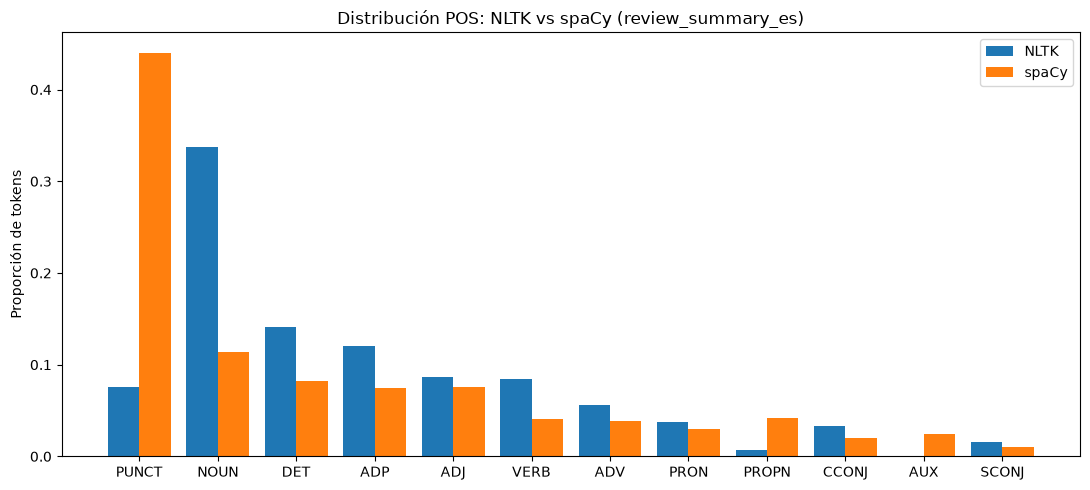

In [17]:
pos_list = [p for p, _ in (dist_nltk + dist_spacy).most_common(12)]
x = range(len(pos_list))
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar([i - 0.2 for i in x], [dist_nltk[p] / tok_nltk for p in pos_list], 0.4, label="NLTK")
ax.bar([i + 0.2 for i in x], [dist_spacy[p] / tok_spacy for p in pos_list], 0.4, label="spaCy")
ax.set_xticks(list(x)); ax.set_xticklabels(pos_list)
ax.set_ylabel("Proporción de tokens")
ax.set_title(f"Distribución POS: NLTK vs spaCy ({COLUMN})")
ax.legend(); plt.tight_layout()
plt.savefig("comparacion_pos.png", dpi=150)
plt.show()